# Les députés sont-ils à l'image de leurs électeurs ? Une analyse de la représentativité des citoyens par leurs élus. 

## Introduction


La démocratie représentative repose sur un principe fondamental : les élus de la Nation sont chargés de porter la voix, les préoccupations et les intérêts de l'ensemble des citoyens. En science politique, on distingue généralement deux dimensions à cette légitimité démocratique : la représentation substantielle, qui désigne la capacité des parlementaires à défendre les idées et les intérêts matériels de leurs mandants, et la représentation descriptive, qui mesure le degré de ressemblance socio-démographique (en termes d'âge, de genre ou d'origine sociale) entre l'assemblée élue et la population qu'elle représente.
Or, depuis quelques années, est souvent soulignée le manque de représentativité des citoyens par leurs élus, que cela soit du point de vue de l'origine sociale ou encore du genre. Dans notre projet, nous souhaitons interroger cette représentativité au sein de la seule chambre élue au suffrage universel, à savoir l'Assemblée nationale. 

**Problématique:** Plus particulièrement, les députés ressemblent-ils aux électeurs de leur circonscription ?

Pour répondre à cette problématique, nous croisons deux sources de données publiques : la base des députés actifs de l'Assemblée nationale (issue de data.gouv.fr / Datan, renseignant leur âge, leur genre, leur groupe politique et leur profession) et les indicateurs statistiques de l'INSEE mesurés à l'échelle fine des 577 circonscriptions législatives (structure par âge, taux d'activité, répartition par catégorie socioprofessionnelle et niveau de vie médian).


### Sommaire

- **Introduction**

- **I. Création et exploration de la base de données principale**
    - A. Récupération et gel des données sources
    - B. Nettoyage, harmonisation des clés et jointure des tables
        - _1. Harmonisation_
        - _2. Jointures_
    - C. Contrôle des données 
        - _1. Structure et dimension de la base_
        - _2. Valeurs manquantes_
        - _3. Cohérence et unicité des observations_
        
- **II. Visualisations, cartographie et statistiques descriptives**
    - A. Exploration univariée : qui sont les députés ? Qui sont les électeurs ?
        - _1. Profil politique et démographique de l'Assemblée nationale_
        - _2. Disparités socio-économiques des circonscriptions françaises_
    - B. Le député face à sa circonscription : trois écarts de représentation
        - _1. L'âge : un décalage générationnel_
        - _2. Le genre : analyse de la parité nationale et de l'ancrage territorial_
        - _3. La catégorie socioprofessionnelle (CSP) : une surreprésentation des cadres indéniable_


- **III. Pour aller plus loin : les caractéristiques d'une circonscription expliquent-elles le genre de l'élu.e ?**
    - A. Les élues sont plus présentes dans les circonscriptions urbaines et favorisées  
    - B. Un effet en partie lié à l'étiquette partisane
    
- **Conclusion**



**Reproductibilité.** Les données sources sont gelées dans le dossier `data/` du dépôt. Pour relancer l'analyse : `pip install -r requirements.txt`, puis exécuter ce notebook de haut en bas. Les fonctions utilisées sont regroupées dans les modules `.py` du dépôt.

# I. Création et exploration de la base de données principale

## A. Récupération et gel des données sources

Dans cette première partie, nous construisons un pipeline reproductible permettant d'importer, de figer (_geler_) et d'assembler les différentes sources de données publiques.

| Nom de la table | Description | Source | Mode d'extraction |
| :--- | :--- | :--- | :--- |
| `deputes` | Informations individuelles des députés actifs (âge, civilité, profession, groupe politique, scores parlementaires). | API data.gouv.fr / Datan | API REST (CSV gelé) |
| `insee_indic` | Indicateurs démographiques et économiques par circonscription législative (structure par âge, emploi, CSP, niveau de vie). | INSEE (Recensement & Filosofi) | Fichier Excel (XLSX gelé) |
| `insee_compo` | Table de passage entre communes et circonscriptions législatives. | INSEE | Fichier Excel (XLSX gelé) |
| `contours` | Géométries des 577 circonscriptions législatives françaises (métropole et outre-mer). | data.gouv.fr (J. Desboeufs) | GeoJSON gelé |

In [ ]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

# Imports des modules du projet
from extraction_donnees import (
    charger_donnees,
    gel_bases_clean,
    gel_donnees_deputes,
    gel_donnees_insee,
)
from jointures import joindre_deputes_insee
from descriptif import (
    preparer_deputes,
    tableau_groupes,
    valeurs_manquantes,
    graphique_deputes,
    graphique_insee,
    taux_chomage,
)
from professions import ajouter_categorie_job
from collecte_contours import gel_contours, charger_contours
from cartes import (
    ajouter_code_circo,
    preparer_carte,
    carte_indicateur,
    carte_genre,
    carte_csp,
    carte_groupes,
)
from representativite import (
    preparer_comparaison,
    correlations_age,
    graphique_age,
    test_correlation_age,
    comparer_csp,
    graphique_csp,
    part_cadres_par_quartile,
    comparer_genre,
    comparer_genre_intra_groupe,
    profil_par_groupe,
    correlation_groupes,
)
# Chargement et préparation initiale des bases
deputes, insee_indic, insee_compo, dico_insee = charger_donnees()
deputes = ajouter_categorie_job(preparer_deputes(deputes))

# Jointure complète et calcul des indicateurs dérivés
df_complet = joindre_deputes_insee(deputes, insee_indic)
df_complet["taux_chomage"] = taux_chomage(df_complet)
df_complet["part_femmes_pop"] = (
    (df_complet["actemp_hom"] - df_complet["actemp"])
    / (df_complet["actemp_hom"] - df_complet["actemp_fem"])
    * 100
)

print("Députés :", deputes.shape)
print("Indicateurs INSEE :", insee_indic.shape)
print("Composition communes-circonscriptions :", insee_compo.shape)
print("Base complète jointe :", df_complet.shape)

Députés : (574, 30)
Indicateurs INSEE : (567, 125)
Composition communes-circonscriptions : (35150, 8)
Base complète jointe : (574, 157)


## B. Nettoyage, harmonisation des clés et jointure des tables

### _1. Harmonisation_

Le principal défi technique de l'assemblage réside dans l'harmonisation de l'identifiant unique de circonscription (`code_circo`) au format standardisé de l'INSEE sur 5 caractères :
- **France métropolitaine** : code département sur 2 caractères (`01` à `95`, incluant `2A` et `2B` en majuscules pour la Corse) + numéro de circonscription sur 3 chiffres (`001`, `018`, etc.).
- **Outre-mer** : code département sur 3 chiffres (`971` à `976`) + numéro de circonscription sur 2 chiffres (`01`, `02`, etc.).
- **Cas particulier des collectivités d'outre-mer** : l'INSEE regroupe Saint-Barthélemy (`97701`) et Saint-Martin (`97801`) sous un même code statistique (`97801`), harmonisation que nous appliquons dans la base des députés.
- **Français établis hors de France** : les 11 circonscriptions de l'étranger (`99` / `ZZ`) n'ont pas d'équivalent territorial dans le recensement INSEE métropolitain/DROM.

Nous enrichissons également la table des députés en créant la variable `genre` à partir de la civilité, l'ancienneté parlementaire en années (`experience_ans`), ainsi qu'une nomenclature harmonisée des catégories socioprofessionnelles (`csp_depute`) permettant la comparaison directe avec les postes de l'INSEE.

In [ ]:
# Aperçu de la table jointe (construite plus haut)
display(
    df_complet[[
        "code_circo",
        "nom",
        "prenom",
        "genre",
        "age",
        "csp_depute",
        "groupeAbrev",
        "act_cad",
        "nivvie_median_diff",
    ]].head(10)
)

,code_circo,nom,prenom,genre,age,csp_depute,groupeAbrev,act_cad,nivvie_median_diff
0,33004,David,Alain,Homme,77,cad,SOC,11.5,20580.0
1,91006,Guedj,Jérôme,Homme,54,cad,SOC,31.5,25090.0
2,64003,Habib,David,Homme,65,cad,LIOT,10.3,21530.0
3,94008,Herbillon,Michel,Homme,75,cad,DR,34.4,27320.0
4,19001,Hollande,François,Homme,72,cad,SOC,9.1,21130.0
5,59021,Létard,Valérie,Femme,64,cad,LIOT,13.7,19430.0
6,15002,Bony,Jean-Yves,Homme,71,agr,DR,6.1,19970.0
7,50001,Gosselin,Philippe,Homme,60,cad,DR,8.2,20850.0
8,73002,Rolland,Vincent,Homme,56,politique,DR,8.6,22490.0
9,53003,Favennec-Bécot,Yannick,Homme,68,politique,LIOT,6.6,20770.0


### _2. Jointure_

La jointure est faite à gauche sur `code_circo` : sur 574 députés, **563 ont les indicateurs INSEE de leur circonscription**. Les 11 restants sont les circonscriptions des Français de l'étranger (`99001` à `99011`), pour lesquelles l'INSEE ne publie pas d'indicateurs. Nous les conservons avec des valeurs manquantes, car ils restent utiles pour les statistiques sur les députés eux-mêmes.

Côté INSEE, trois circonscriptions n'ont pas de député dans la base : l'Aube (2e), la Charente-Maritime (5e) et la Gironde (11e). Leurs titulaires ont été élus sénateurs fin septembre 2026 et ont été remplacés par leurs suppléants, qui ne figurent pas encore dans le fichier des députés téléchargé le 14 novembre 2026. La ligne `00000` de l'INSEE est une moyenne nationale, pas une circonscription : elle est exclue.

## C. Contrôle des données 

### _1. Structure et dimension de la base_ 

In [16]:
print("Dimensions de la table jointe :", df_complet.shape)
print(
    "Nombre de circonscriptions avec données INSEE :",
    df_complet["indicateur_present"].sum(),
)
print(
    "Nombre de circonscriptions avec un député actif :",
    df_complet["id"].notna().sum(),
)

Dimensions de la table jointe : (574, 157)
Nombre de circonscriptions avec données INSEE : 563
Nombre de circonscriptions avec un député actif : 574


La table finale compte 574 lignes (un député par ligne) et 157 colonnes. Parmi elles, 563 députés sont rattachés à une circonscription couverte par l'INSEE ; les 11 autres sont élus des Français de l'étranger (voir ci-dessus). Trois circonscriptions n'ont pas de député dans la base (sièges vacants).

### _2. Valeurs manquantes_

In [17]:
display(valeurs_manquantes(df_complet).head(15))

,nb,pct
website,363,63.2
facebook,257,44.8
twitter,218,38.0
mfuel,38,6.6
iranr_dep,37,6.4
ilt_dep,37,6.4
PPAT,27,4.7
PPSOC,27,4.7
PIMPOT,27,4.7
part_plutot_aises_diff,27,4.7


Les variables les plus incomplètes sont les réseaux sociaux et le site web des députés (38 % à 63 % de valeurs manquantes), que nous n'utilisons pas. Les indicateurs INSEE de revenus et de pauvreté manquent pour 27 circonscriptions (4,7 %) : les 11 de l'étranger, non couvertes, et 16 en outre-mer, où ces données ne sont pas diffusées. Les analyses sur le niveau de vie portent donc uniquement sur la métropole, ce qui limite leur portée pour l'outre-mer.

### _3. Cohérence et unicité des observations_

In [18]:
print("Doublons sur code_circo :", df_complet["code_circo"].duplicated().sum())
print(
    "Âge min / max des députés :",
    df_complet["age"].min(),
    "/",
    df_complet["age"].max(),
)
print(
    "Niveau de vie médian min / max (€) :",
    df_complet["nivvie_median_diff"].min(),
    "/",
    df_complet["nivvie_median_diff"].max(),
)

Doublons sur code_circo : 0
Âge min / max des députés : 25 / 83
Niveau de vie médian min / max (€) : 14070.0 / 39590.0


Aucun doublon n'est présent sur le code de circonscription : chaque circonscription a au plus un député. Les valeurs extrêmes sont plausibles (âge des députés de 25 à 83 ans, niveau de vie médian de 14 070 € à 39 590 €), ce qui ne suggère pas d'erreur de saisie.

# II. Visualisations, cartographie et statistiques descriptives

## A. Exploration univariée : qui sont les députés ? Qui sont les électeurs ?

### _1. Profil politique et démographique de l'Assemblée nationale_

,effectif,age_moyen,part_femmes
groupeAbrev,,,
RN,121,50.2,32.2
EPR,90,53.1,50.0
LFI-NFP,70,44.3,42.9
SOC,68,56.2,41.2
DR,46,54.5,30.4
ECOS,38,49.8,47.4
DEM,37,57.7,40.5
HOR,35,55.8,34.3
LIOT,24,59.4,25.0


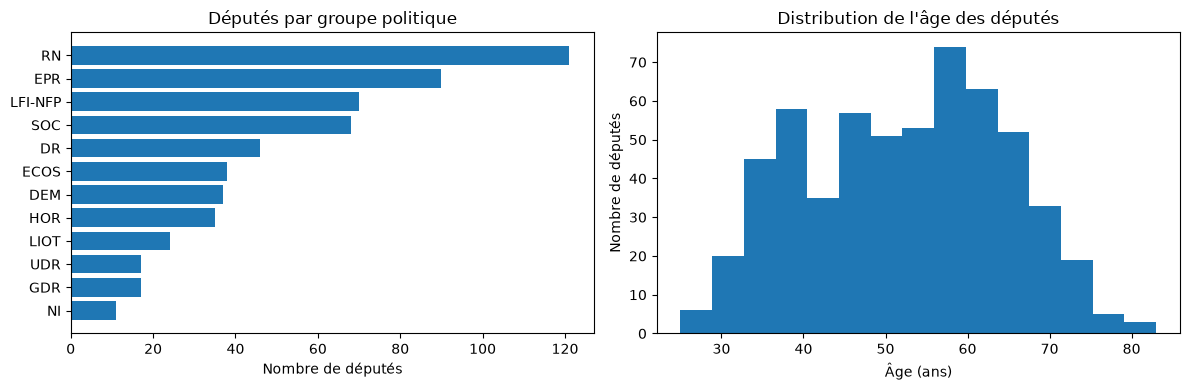

In [19]:
display(tableau_groupes(deputes))
graphique_deputes(deputes);

L'Assemblée compte 574 députés actifs répartis en 12 groupes, dont 39 % de femmes (220). Le RN (121 députés) et EPR (90) sont les groupes les plus nombreux. Trois groupes (GDR, UDR, NI) comptent moins de 20 députés : toute moyenne calculée sur eux sera peu fiable.

L'âge moyen des députés est d'environ 52 ans, mais il varie fortement selon les groupes : de 44 ans pour LFI-NFP et l'UDR à 59 ans pour LIOT. La parité varie aussi beaucoup, de 50 % de femmes chez EPR à 18 % à l'UDR. Ces écarts entre groupes justifient de ne pas traiter les députés comme un ensemble homogène dans la suite.

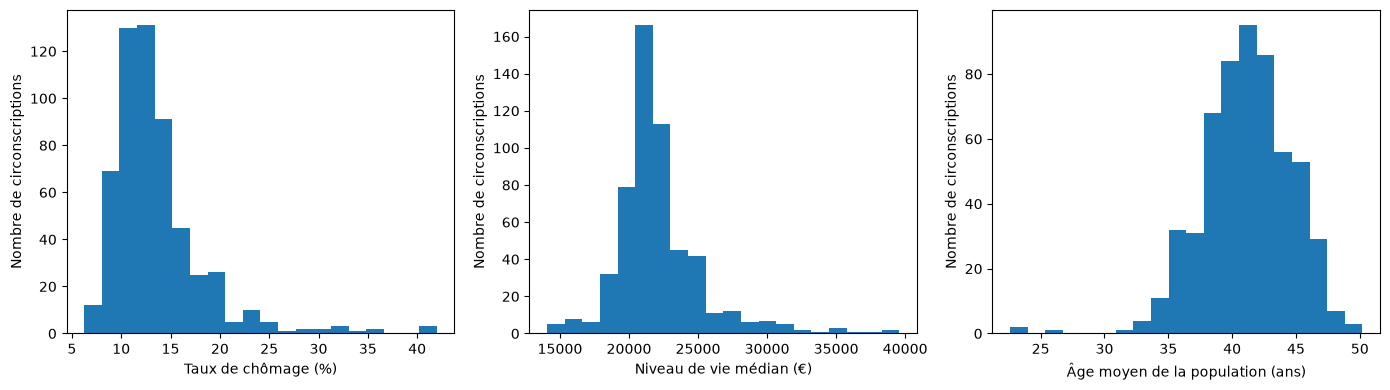

In [21]:
graphique_insee(df_complet);

Les circonscriptions diffèrent nettement. Le taux de chômage (calculé comme chômeurs / population active, au sens du recensement, donc plus élevé que le taux officiel) a une médiane de 12,6 % et va de 6,2 % à 42 %. Les valeurs les plus élevées sont toutes en outre-mer (Mayotte, Guyane, La Réunion : de 36 % à 42 %), ce qui en fait des cas atypiques. Le niveau de vie médian va de 14 070 € à 39 590 € (médiane 21 590 €). L'âge moyen de la population, autour de 41 ans, est bien inférieur à celui des députés, mais les deux ne sont pas strictement comparables (l'âge INSEE inclut les enfants). Le niveau de vie médian est manquant pour 16 circonscriptions, toutes situées en outre-mer, que la source (Filosofi) ne semble pas couvrir.

## B. Le député face à sa circonscription : trois écarts de représentation

### _1. L'âge : un décalage générationnel_



         age  dec50  ecart_age
count  563.0  563.0      563.0
mean    52.2   41.4       10.8
std     12.2    5.1       12.4
min     25.0   17.0      -19.0
25%     42.0   38.0        2.0
50%     53.0   42.0       12.0
75%     61.0   45.0       19.0
max     83.0   55.0       41.0
toutes circonscriptions    0.17
métropole seule            0.18
dtype: float64
(np.float64(0.17849904160116345), np.float64(3.234018329464958e-05))


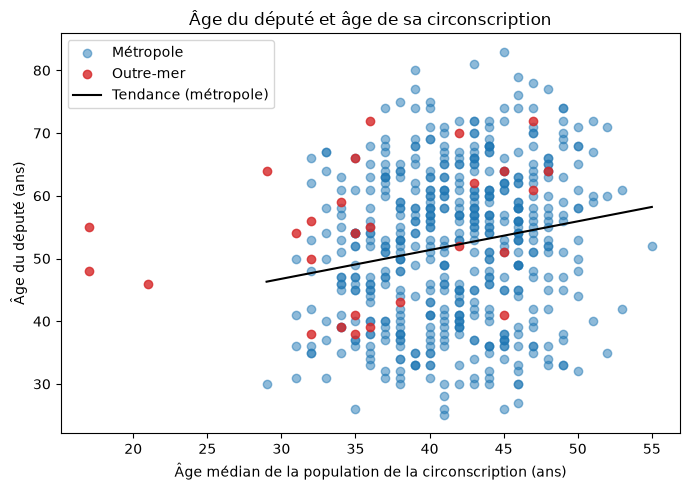

In [ ]:
comp = preparer_comparaison(df_complet)
print(comp[["age", "dec50", "ecart_age"]].describe().round(1))
print(correlations_age(comp).round(2))
graphique_age(comp);
print(test_correlation_age(comp))

Le croisement des données de l'Assemblée nationale et de l'INSEE (sur les 563 circonscriptions renseignées) montre que l'âge des parlementaires est largement déconnecté de la pyramide des âges de leurs électeurs. En premier lieu, on observe un décalage générationnel important : les députés ont en moyenne environ 11 ans de plus que l'âge médian de la population de leur circonscription — un écart qui s'explique en partie par la présence des mineurs dans les données INSEE, mais qui confirme la surreprésentation des générations plus âgées dans l'hémicycle.   

Surtout, la structure démographique locale n'influence presque pas le profil d'âge de l'élu. La corrélation entre l'âge médian d'une circonscription et celui de son député est extrêmement faible (0,17 sur l'ensemble du territoire et 0,18 en métropole, test de Pearson, p-value < 0,001), ce qui signifie que la pyramide des âges locale n'explique qu'environ 3 % de la variation de l'âge des députés. Ainsi, à profil démographique identique, l'âge des élus s'étend indifféremment de 25 à 83 ans. Même dans les circonscriptions d'outre-mer nettement plus jeunes (où l'âge médian descend entre 17 et 21 ans pour trois d'entre elles), les électeurs n'élisent pas des députés sensiblement plus jeunes qu'en métropole. L'âge des députés apparaît donc faiblement lié à la composition démographique des territoires qu'ils représentent.

### _2. Le genre : parité et ancrage territorial_

Nous examinons maintenant le genre. Les deux cartes ci-dessous comparent la part de femmes dans la population de chaque circonscription et le genre du député élu. Les tests statistiques sont présentés en partie III.

In [ ]:
carte = preparer_carte()

contours_circonscriptions.geojson déjà présent : pas de téléchargement.


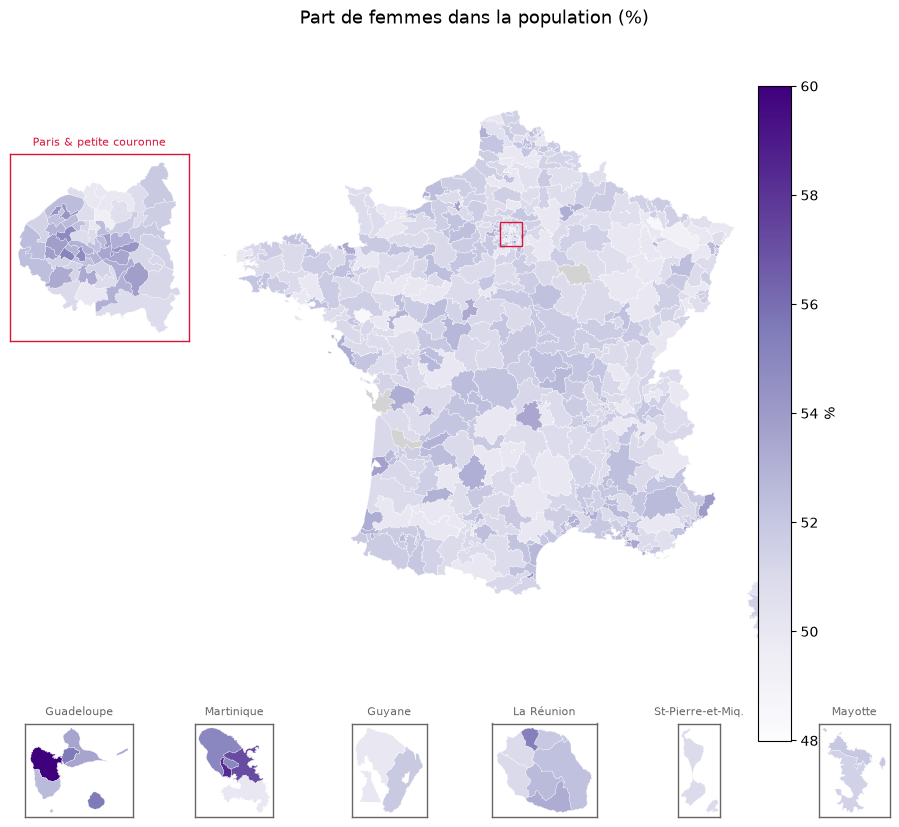

In [26]:
carte_indicateur(
    carte,
    "part_femmes",
    "Part de femmes dans la population (%)",
    cmap="Purples",
)
plt.show()

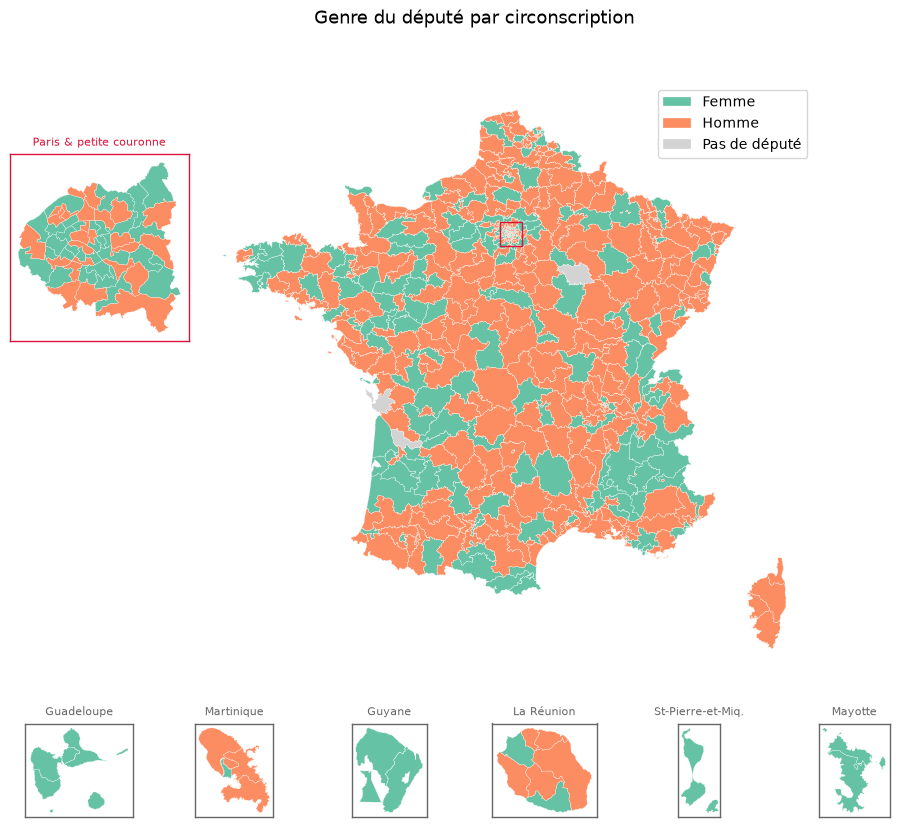

In [27]:
from cartes import carte_genre
carte_genre(carte);

La part de femmes dans la population est très homogène : dans presque toutes les circonscriptions métropolitaines, elle se situe entre 50 % et 54 %. À l'inverse, le genre des élus varie beaucoup d'un territoire à l'autre : les hommes sont majoritaires presque partout, la Corse n'a aucune élue, et les circonscriptions représentées par des femmes sont davantage concentrées dans les zones urbaines, notamment à Paris et en petite couronne. Le genre de l'élu(e) ne reflète donc pas la composition démographique locale. Cela suggère que d'autres facteurs interviennent (urbanisation, groupe politique), que nous testons en partie III.

### _3. La catégorie socio-professionnelle (CSP) ou la surreprésentation des cadres à l'Assemblée nationale_

In [ ]:
display(deputes["csp_depute"].value_counts().to_frame("effectif"))

,effectif
csp_depute,
cad,347
art,55
int,40
non_classe,33
inactif,29
emp,27
politique,22
agr,16
ouv,5


Députés classés : 490


,deputes,population_active,ecart
Agriculteurs exploitants,3.3,1.4,1.8
"Artisans, commerçants, chefs d'entreprise",11.2,6.3,4.9
Cadres et prof. intellectuelles supérieures,70.8,16.0,54.8
Professions intermédiaires,8.2,24.6,-16.4
Employés,5.5,28.4,-22.8
Ouvriers,1.0,21.4,-20.4


,effectif,part_deputes_cadres,part_cadres_circo
quartile_cadres,,,
Q1 (moins de cadres),120,65.8,8.3
Q2,111,71.2,11.0
Q3,112,70.5,15.3
Q4 (plus de cadres),114,75.4,29.5


p-value (chi2) : 0.45402189372534496


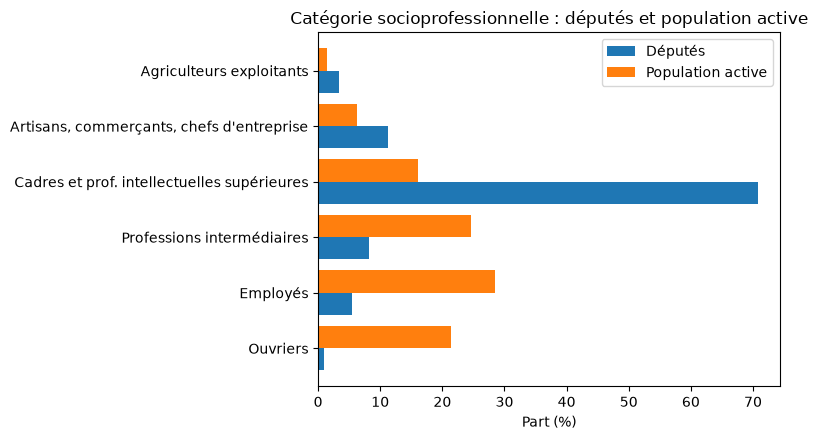

In [ ]:
tab_csp = comparer_csp(deputes, insee_indic)
print("Députés classés :", tab_csp.attrs["effectif"])
display(tab_csp)
graphique_csp(tab_csp);

comp_csp = ajouter_categorie_job(comp)
quartiles = part_cadres_par_quartile(comp_csp)
display(quartiles)
print("p-value (chi2) :", quartiles.attrs["p_value"])

Nous recodons la profession déclarée de chaque député en six grandes catégories comparables à celles de l'INSEE (règles dans `professions.py`) : la nomenclature PCS lorsque la profession est codée (20 % des députés), des règles par mots-clés sinon. Sur 574 députés, 490 sont classés ; 84 sont exclus de la comparaison (22 collaborateurs ou membres de cabinets, 29 personnes sans activité ou retraitées sans ancien métier connu, 33 libellés trop ambigus).

Les cadres et professions intellectuelles supérieures représentent 70,8 % des députés classés, contre 16,0 % de la population active. À l'inverse, les employés (5,5 % contre 28,4 %) et les ouvriers (1,0 % contre 21,4 %) sont très peu présents : à eux deux, ils forment près de la moitié des actifs mais 6,5 % des députés. Les professions intermédiaires sont également sous-représentées (8,2 % contre 24,6 %). Les artisans, commerçants et chefs d'entreprise (11,2 % contre 6,3 %) et les agriculteurs exploitants (3,3 % contre 1,4 %) sont un peu surreprésentés, mais les effectifs sont faibles (16 agriculteurs et 5 ouvriers parmi les députés classés), ce qui rend ces parts fragiles.

Cette surreprésentation ne dépend pas de la circonscription : la part de députés cadres est de 66 % dans le quart des circonscriptions comptant le moins de cadres et de 75 % dans celui qui en compte le plus, mais cette différence n'est pas significative (test du chi2, p = 0,45). Même dans les territoires où les cadres sont rares, les élus sont très majoritairement cadres.

Ces résultats reposent sur la profession déclarée par les députés, qui peut valoriser leur parcours, et sur un recodage en partie subjectif (règles détaillées dans le code, 5,7 % de libellés non classés).

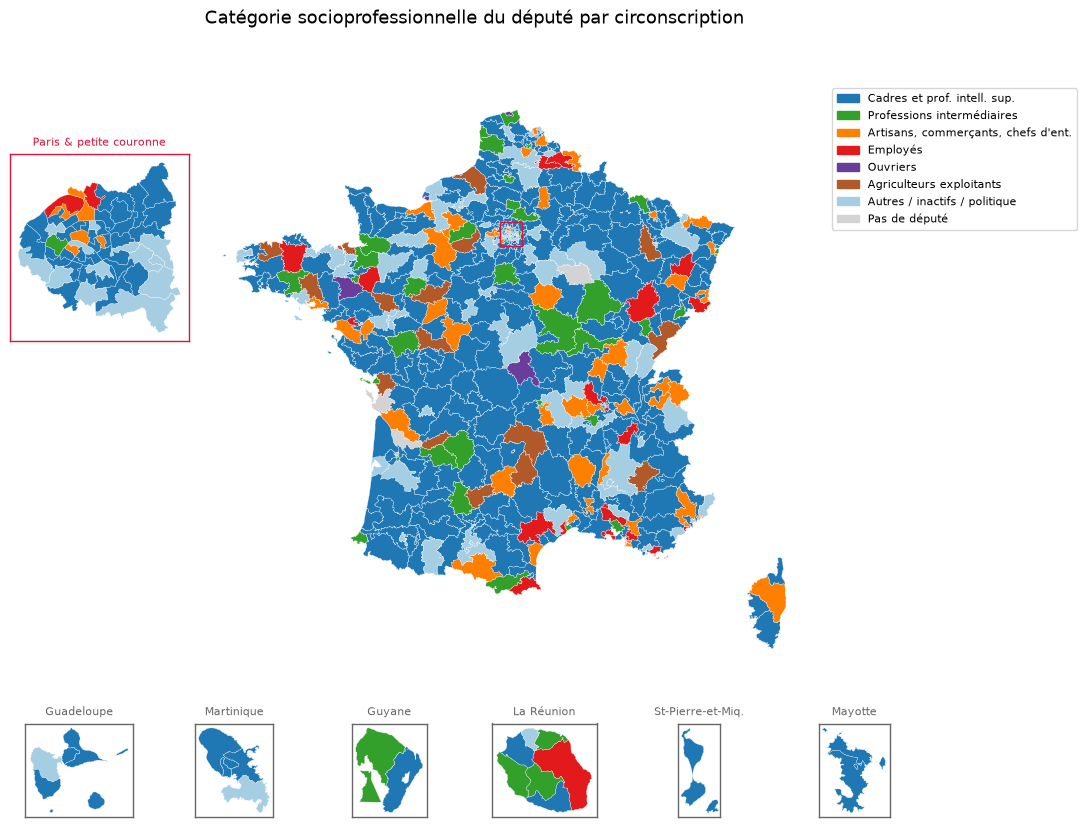

In [34]:
carte_csp(carte);

contours_circonscriptions.geojson déjà présent : pas de téléchargement.


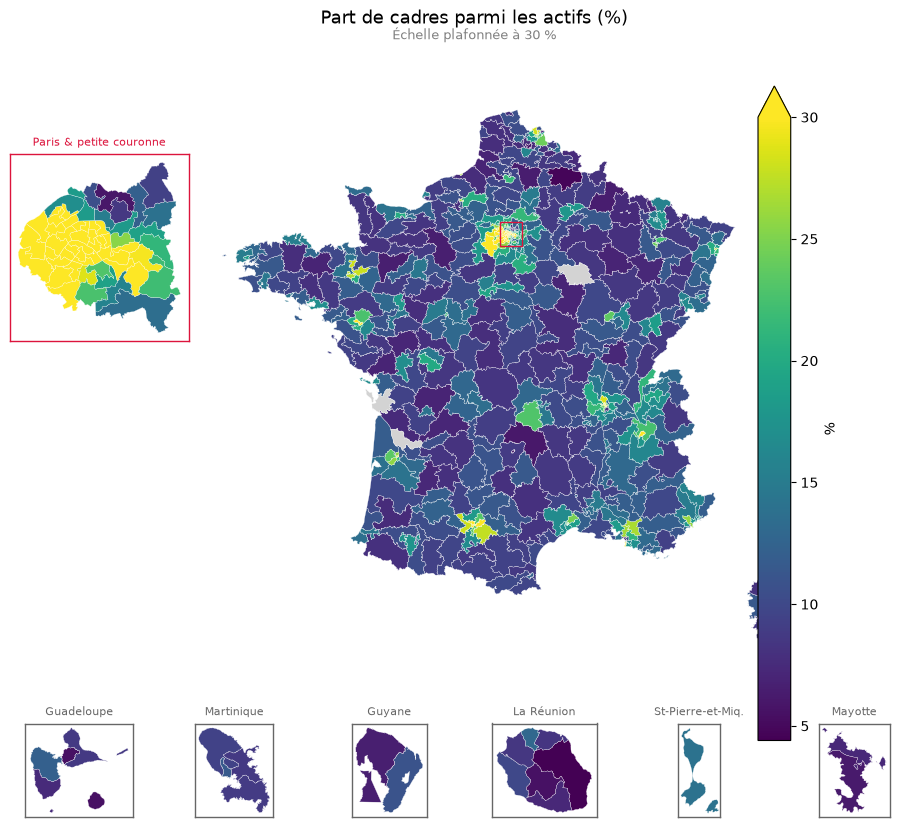

In [ ]:
carte_indicateur(carte, "act_cad", "Part de cadres parmi les actifs (%)", vmax=30);

La part de cadres parmi les actifs est élevée dans quelques pôles (Paris, petite couronne, grandes agglomérations) et faible dans l'essentiel du territoire. La carte des députés, elle, est presque entièrement occupée par la catégorie « cadres et professions intellectuelles supérieures », y compris dans les circonscriptions rurales, périurbaines ou ouvrières. Les autres catégories, en particulier les ouvriers et les employés, sont presque absentes. Le profil socioprofessionnel des élus ne reflète donc pas la diversité sociale des électeurs, quel que soit le territoire, ce qui confirme les résultats du tableau précédent.

**Bilan de la partie II.** Sur les trois dimensions étudiées, les députés ne sont pas le miroir de leur circonscription : ils sont plus âgés, très majoritairement cadres et, pour 38 % seulement, des femmes. L'écart est le plus fort pour la profession, et il ne varie presque pas avec le territoire. Le cas du genre, qui varie davantage selon le contexte local, est approfondi dans la partie suivante.

# III. Pour aller plus loin : les caractéristiques d'une circonscription expliquent-elles le genre de son député ?

## A. Les élues sont plus présentes dans les circonscriptions urbaines et favorisées

In [ ]:
tab_genre = comparer_genre(comp)
print("Effectifs (femmes, hommes) :", tab_genre.attrs["effectifs"])
display(tab_genre.round(3))

Effectifs (femmes, hommes) : (209, 327)


,moyenne_femmes,moyenne_hommes,ecart,p_value
indicateur,,,,
Part de la population dans un pôle urbain (%),54.352,47.537,6.815,0.013
Part de la population en commune rurale non périurbaine (%),12.682,16.631,-3.949,0.019
Niveau de vie médian (€),22819.426,21913.333,906.093,0.003
Taux de pauvreté (%),14.279,14.787,-0.508,0.301
Part de cadres parmi les actifs (%),18.069,14.874,3.195,0.000
Part d'ouvriers parmi les actifs (%),20.058,22.763,-2.705,0.000
Part d'actifs diplômés bac+5 ou plus (%),15.715,12.422,3.293,0.000
Taux de chômage (%),12.693,13.118,-0.424,0.194
Âge médian de la population (ans),41.177,42.058,-0.881,0.028


Sur neuf indicateurs testés (test de Mann-Whitney), sept diffèrent significativement selon le genre de l'élu(e) (p < 0,05). Les femmes sont élues dans des circonscriptions plus urbaines (54,4 % de la population en pôle urbain contre 47,5 % pour les hommes), plus aisées (niveau de vie médian de 22 819 € contre 21 913 €), plus riches en cadres et diplômés de niveau bac+5 (18,1 % de cadres contre 14,9 %) et moins ouvrières (20,1 % contre 22,8 %). En revanche, les taux de pauvreté et de chômage ne diffèrent pas significativement. Ces écarts bruts peuvent venir en partie du groupe politique de l'élu(e) : nous les contrôlons ci-dessous.

In [ ]:
tab_intra = comparer_genre_intra_groupe(comp)
print("Groupes gardés :", tab_intra.attrs["groupes"])
print("Circonscriptions :", tab_intra.attrs["effectif"])
display(tab_intra.round(3))

Groupes gardés : ['DEM', 'DR', 'ECOS', 'EPR', 'HOR', 'LFI-NFP', 'RN', 'SOC']
Circonscriptions : 480


,ecart_intra_groupe,p_value
indicateur,,
Part de cadres parmi les actifs (%),1.895,0.046
Part d'actifs diplômés bac+5 ou plus (%),1.990,0.065
Part d'ouvriers parmi les actifs (%),-1.882,0.001
Niveau de vie médian (€),685.165,0.051
Part de la population dans un pôle urbain (%),3.958,0.075


À groupe politique identique, deux écarts restent significatifs : les femmes sont élues dans des circonscriptions comptant moins d'ouvriers (−1,9 point ; p = 0,001) et plus de cadres (+1,9 point ; p = 0,046). Les écarts sur l'urbanisation (+4,0 points), le diplôme (+2,0 points) et le niveau de vie (+685 €) vont dans le même sens mais ne sont pas significatifs au seuil de 5 % (p compris entre 0,051 et 0,075) ; nous les considérons comme des tendances. L'effet du genre sur la composition sociale des circonscriptions existe donc encore une fois le groupe politique pris en compte, mais il est plus faible.

## B. Un effet en partie lié à l'étiquette partisane

In [ ]:
tab_groupes = profil_par_groupe(comp)
display(tab_groupes)
print("p-value (Kruskal-Wallis) :", tab_groupes.attrs["p_kruskal"])

,effectif,part_femmes,part_cadres_circo,niveau_vie_median
groupeAbrev,,,,
ECOS,37,48.6,23.1,22644.6
EPR,78,52.6,22.1,24899.0
LFI-NFP,67,44.8,18.7,20759.9
SOC,63,42.9,18.3,22684.8
HOR,35,34.3,15.8,23323.7
DEM,35,42.9,15.2,22930.0
DR,46,30.4,13.9,22744.6
RN,119,31.9,10.6,20951.5


p-value (Kruskal-Wallis) : 7.308025280017948e-23


In [ ]:
r, p = correlation_groupes(tab_groupes)
print(f"Corrélation de Spearman : {r:.2f} (p = {p:.3f})")

Corrélation de Spearman : 0.91 (p = 0.002)


Contrairement à l'analyse précédente qui opposait directement les élues aux élus, cette étape compare les 8 principaux groupes politiques entre eux (480 circonscriptions) afin de tester l'existence d'un facteur de confusion partisan : les groupes qui élisent le plus de femmes sont-ils ceux dont l'ancrage électoral se situe dans des territoires favorisés ?

Le test non paramétrique de Kruskal-Wallis montre d'abord que le profil socio-économique des circonscriptions varie très significativement d'un groupe à l'autre (p = 7,31e-23). Le tableau ci-dessus fait ensuite apparaître deux ensembles :

- **Les groupes les plus féminisés** (EPR 52,6 % de femmes, Écologistes 48,6 %, LFI-NFP 44,8 %, Socialistes 42,9 %) sont élus dans des circonscriptions plus riches en cadres (de 18,3 % à 23,1 %), avec les niveaux de vie médians les plus élevés (jusqu'à 24 899 € pour EPR). Ces circonscriptions sont surtout situées dans les grands pôles urbains (Paris et petite couronne, Ouest, grandes agglomérations).
- **Les groupes les moins féminisés** sont élus dans des circonscriptions moins dotées en cadres : le RN (31,9 % de femmes, 10,6 % de cadres), implanté dans le Nord-Est, le pourtour méditerranéen et la vallée de la Garonne, et la Droite Républicaine (30,4 % de femmes, 13,9 % de cadres), ancrée dans des territoires plus ruraux.

Cette association est confirmée par la corrélation de Spearman calculée entre les groupes (0,91 ; p = 0,002) : plus la part de cadres est élevée dans les circonscriptions d'un groupe, plus la part de femmes parmi ses députés l'est aussi. Ce résultat repose toutefois sur 8 groupes seulement, et porte sur des moyennes de groupes et non sur des circonscriptions : il montre que l'étiquette partisane est un facteur de confusion important, sans permettre de conclure à un lien de cause à effet.

La carte ci-dessous illustre cette polarisation géographique des groupes.

contours_circonscriptions.geojson déjà présent : pas de téléchargement.


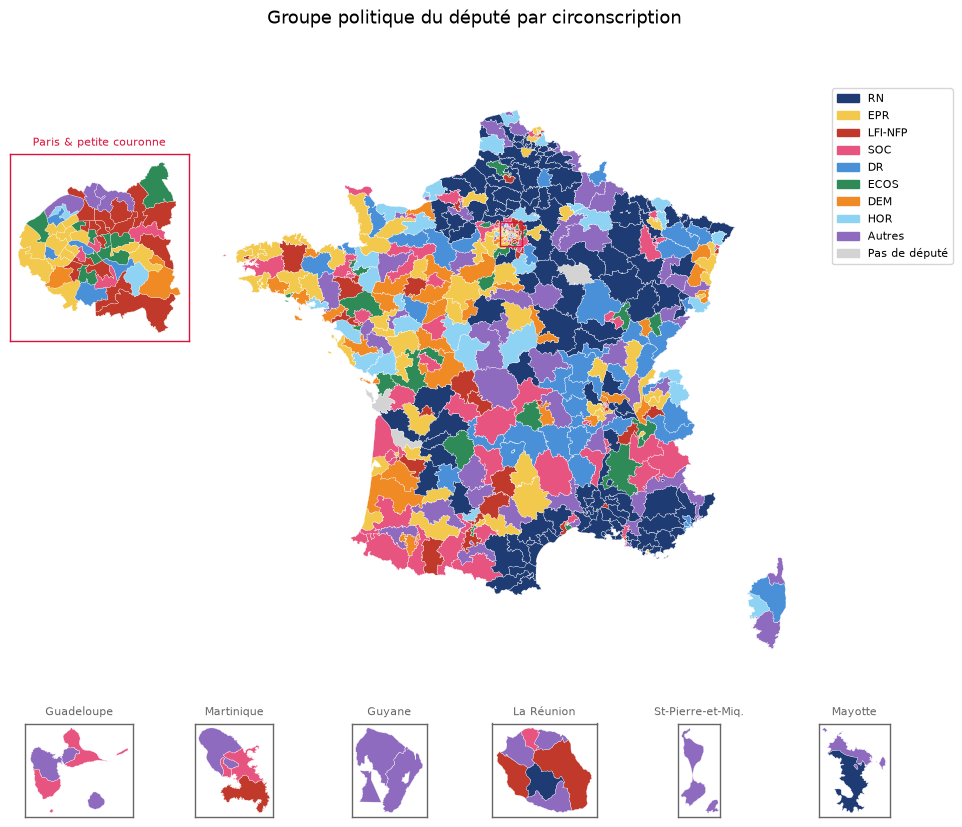

In [ ]:
carte_groupes(carte);

# Conclusion

Ainsi, les députés ne sont pas à l'image de leurs électeurs. Pour le montrer, nous avons comparé les 574 députés en exercice aux caractéristiques INSEE de leur circonscription. L'écart est net sur l'âge, la profession et, dans une moindre mesure, le genre. Surtout, il ne dépend presque pas du territoire.

Sur l'âge, les députés ont en moyenne 52 ans, soit environ 11 ans de plus que l'âge médian de leur circonscription. Cet écart est en partie mécanique, car l'INSEE compte les mineurs. Mais l'âge de l'élu n'est que très faiblement lié à celui de ses électeurs (corrélation de 0,17, soit environ 3 % de la variation expliquée). Une circonscription jeune n'élit donc pas un député sensiblement plus jeune.

Sur la profession, l'écart est le plus fort. Les cadres et professions intellectuelles supérieures forment 70,8 % des députés dont la profession a pu être classée, contre 16,0 % de la population active. À l'inverse, les employés et les ouvriers, qui représentent près de la moitié des actifs, ne sont que 6,5 % des députés. Cette surreprésentation se retrouve même dans les circonscriptions où les cadres sont peu nombreux : 66 % des députés y sont cadres, contre 75 % dans celles où ils sont les plus nombreux, et cette différence n'est pas significative.

Sur le genre, les femmes représentent 38 % des députés. Elles sont plus souvent élues dans des circonscriptions urbaines, diplômées et aisées, et moins souvent dans des circonscriptions ouvrières. Cet écart tient en partie à l'étiquette partisane : les groupes qui comptent le plus de femmes sont aussi ceux dont les circonscriptions comptent le plus de cadres. Il reste visible, de façon plus fragile, à groupe politique identique.

Toutefois, ces résultats comportent plusieurs limites :
- Les Français de l'étranger, une partie de l'outre-mer et trois sièges vacants sont exclus de certaines analyses.
- Les âges et les CSP ne sont pas strictement comparables (âge médian de toute la population contre âge des élus ; profession déclarée par les députés, recodée en partie par mots-clés, avec 84 députés non classés)
- la corrélation entre groupes politiques ne repose que sur 8 groupes, et relie des moyennes de groupes, pas des circonscriptions

En définitive, l'Assemblée nationale ressemble moins à la population française qu'à une élite diplômée, plus âgée et plus urbaine, y compris lorsqu'elle représente des territoires populaires ou ruraux.


### **Ouverture** ###

Plusieurs pistes permettrait de prolonger notre analyse : intégrer l'origine sociale ou le niveau de diplôme des élus (non disponibles ici), suivre l'évolution de la composition de l'Assemblée sur plusieurs législatures, ou étudier la représentation substantielle (votes et prises de position des députés) en la rapprochant des caractéristiques de leurs circonscriptions. 